<h1 align="center" style="color:green">Fraud Detection Project Modeling and Evaluation</h1>

In [2]:
import pandas as pd

from insurance_fraud_detection.config import RAW_CSV, TARGET, DROP_COLUMNS, CLEANER_PARAMS_PATH
from insurance_fraud_detection.data_prep import load_data, split_data, drop_bad_rows
from insurance_fraud_detection.preprocessing import fit_cleaner, prepare
from insurance_fraud_detection.features import WOEEncoder

%load_ext autoreload
%autoreload 2

In [3]:
df = load_data()
train_df, test_df = split_data(df)
print(f"Train shape: {train_df.shape},\nTest shape: {test_df.shape}")

train_df = drop_bad_rows(train_df)
test_df = drop_bad_rows(test_df)
print(f"Train shape: {train_df.shape},\nTest shape: {test_df.shape}")

params = fit_cleaner(train_df)

Train shape: (12336, 31),
Test shape: (3084, 31)
Train shape: (12335, 31),
Test shape: (3084, 31)


In [4]:
train_ord = prepare(train_df, params)
test_ord = prepare(test_df, params)

print(f"train_ord shape: {train_ord.shape},\ntest_ord shape: {test_ord.shape}")  # expect (12335, 31) and (3084, 31)

train_ord shape: (12335, 31),
test_ord shape: (3084, 31)


In [5]:
from insurance_fraud_detection.preprocessing import load_params
assert load_params(CLEANER_PARAMS_PATH) == params
loaded = load_params(CLEANER_PARAMS_PATH)
print(loaded, params, loaded == params)

{'age': 39.0} {'age': 39.0} True


## Feature Engineering & Feature Selection
- WOE & IV


In [6]:
CANDIDATES = [c for c in train_ord.columns if c not in {TARGET, "policy_type", "age"}]

enc = WOEEncoder(cols=CANDIDATES).fit(train_ord[CANDIDATES], train_ord[TARGET])
iv = pd.Series(enc.iv_).sort_values(ascending=False)
print(iv.round(3))

base_policy              0.771
fault                    0.528
vehicle_category         0.491
make                     0.075
past_number_of_claims    0.064
address_change_claim     0.063
deductible               0.059
vehicle_price            0.055
month                    0.051
month_claimed            0.048
age_of_policy_holder     0.028
number_of_suppliments    0.028
agent_type               0.023
age_of_vehicle           0.023
sex                      0.017
year                     0.010
accident_area            0.010
day_of_week              0.009
days_policy_accident     0.009
days_policy_claim        0.006
day_of_week_claimed      0.006
police_report_filed      0.005
week_of_month            0.005
week_of_month_claimed    0.003
number_of_cars           0.001
witness_present          0.001
driver_rating            0.001
marital_status           0.001
dtype: float64


In [7]:
selected = iv[iv >= 0.02].index.tolist()   # 14 columns
selected.remove("vehicle_category")        # proxy for base_policy
print(len(selected), selected)

13 ['base_policy', 'fault', 'make', 'past_number_of_claims', 'address_change_claim', 'deductible', 'vehicle_price', 'month', 'month_claimed', 'age_of_policy_holder', 'number_of_suppliments', 'agent_type', 'age_of_vehicle']


- VIF

In [8]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools import add_constant

def vif_table(woe_df: pd.DataFrame) -> pd.Series:
    X = add_constant(woe_df)  # without the constant, VIF values are distorted
    vif = {
        col: variance_inflation_factor(X.values, i) # type: ignore
        for i, col in enumerate(X.columns) # type: ignore
        if col != "const"
    }
    return pd.Series(vif).sort_values(ascending=False)

In [9]:

from insurance_fraud_detection.config import SELECTED_COLS


woe_train = (
    WOEEncoder(cols=SELECTED_COLS)
    .fit(train_ord[SELECTED_COLS], train_ord[TARGET])
    .transform(train_ord[SELECTED_COLS])
)
print(vif_table(woe_train).round(1))

deductible               4.5
address_change_claim     4.5
month_claimed            2.6
month                    2.6
age_of_vehicle           1.3
age_of_policy_holder     1.3
base_policy              1.2
past_number_of_claims    1.2
vehicle_price            1.1
fault                    1.1
number_of_suppliments    1.0
agent_type               1.0
make                     1.0
dtype: float64


## Model Training
- Logistic Regression

In [10]:
import numpy as np
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.metrics import classification_report

from insurance_fraud_detection.config import SELECTED_COLS, SEED
from insurance_fraud_detection.features import WOEEncoder
from insurance_fraud_detection.evaluate import score_report

TARGET = "fraud_found_p"  # replace with your actual target column name

X_train, y_train = train_ord[SELECTED_COLS], train_ord[TARGET]
X_test, y_test = test_ord[SELECTED_COLS], test_ord[TARGET]

print( f"Train shape: {X_train.shape},\nTest shape: {X_test.shape},\nFraud rate: {y_train.mean().round(4)}" ) # type: ignore

Train shape: (12335, 13),
Test shape: (3084, 13),
Fraud rate: 0.0598


In [11]:
lr_pipe = Pipeline([
    ("woe", WOEEncoder(cols=SELECTED_COLS)),
    ("clf", LogisticRegression(max_iter=1000)),
])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
cv_scores = cross_val_score(
    lr_pipe, X_train, y_train, cv=cv, scoring="average_precision"
)
print("CV PR-AUC per fold:", cv_scores.round(3))
print("\nmean:", cv_scores.mean().round(3), "std:", cv_scores.std().round(3))

lr_pipe.fit(X_train, y_train)
lr_scores = lr_pipe.predict_proba(X_test)[:, 1]
print("\nScore report:")
for k, v in score_report(y_test, lr_scores).items():
    print(f"  {k:<12} {v:.3f}" if isinstance(v, float) else f"  {k:<12} {v}")
print()

cutoff = np.quantile(lr_scores, 0.90)   # flag the top 10% of claims
y_pred = (lr_scores >= cutoff).astype(int)

print(f"\nClassification Report:\n{classification_report(y_test, y_pred, target_names=["not fraud", "fraud"], digits=2)}")

CV PR-AUC per fold: [0.161 0.147 0.15  0.166 0.172]

mean: 0.159 std: 0.009

Score report:
  pr_auc       0.147
  roc_auc      0.796
  gini         0.591
  ks           0.546
  top_caught   50
  total_fraud  185
  lift         2.703


Classification Report:
              precision    recall  f1-score   support

   not fraud       0.95      0.91      0.93      2899
       fraud       0.16      0.27      0.20       185

    accuracy                           0.87      3084
   macro avg       0.56      0.59      0.57      3084
weighted avg       0.90      0.87      0.89      3084



- XGBoost

In [12]:
from xgboost import XGBClassifier

xgb_params = dict(
    n_estimators=300,
    max_depth=3,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=SEED,
)

xgb_pipe = Pipeline([
    ("woe", WOEEncoder(cols=SELECTED_COLS)),
    ("clf", XGBClassifier(**xgb_params)),
])

cv_scores = cross_val_score(
    xgb_pipe, X_train, y_train, cv=cv, scoring="average_precision"
)
print("CV PR-AUC per fold:", cv_scores.round(3))
print("\nmean:", cv_scores.mean().round(3), "std:", cv_scores.std().round(3))

xgb_pipe.fit(X_train, y_train)
xgb_scores = xgb_pipe.predict_proba(X_test)[:, 1]
print("\nScore report:")
for k, v in score_report(y_test, xgb_scores).items():
    print(f"  {k:<12} {v:.3f}" if isinstance(v, float) else f"  {k:<12} {v}")
print()

cutoff = np.quantile(xgb_scores, 0.90)
y_pred = (xgb_scores >= cutoff).astype(int)
print(f"\nClassification Report:\n{classification_report(y_test, y_pred, target_names=["not fraud", "fraud"], digits=2)}")

CV PR-AUC per fold: [0.193 0.241 0.206 0.227 0.229]

mean: 0.219 std: 0.017

Score report:
  pr_auc       0.225
  roc_auc      0.818
  gini         0.635
  ks           0.551
  top_caught   55
  total_fraud  185
  lift         2.973


Classification Report:
              precision    recall  f1-score   support

   not fraud       0.95      0.91      0.93      2899
       fraud       0.18      0.30      0.22       185

    accuracy                           0.88      3084
   macro avg       0.57      0.60      0.58      3084
weighted avg       0.91      0.88      0.89      3084



- Comparing with the base model

In [13]:
import pandas as pd

def run(clf, cols: list) -> dict:
    pipe = Pipeline([("woe", WOEEncoder(cols=cols)), ("clf", clf)])
    cv_s = cross_val_score(
        pipe, X_train[cols], y_train, cv=cv, scoring="average_precision"
    )
    pipe.fit(X_train[cols], y_train)
    r = score_report(y_test, pipe.predict_proba(X_test[cols])[:, 1])
    return {"cv_mean": cv_s.mean(), "cv_std": cv_s.std(), **r}

ladder = {
    "LR basic": run(LogisticRegression(max_iter=1000), SELECTED_COLS),
    "XGB defaults": run(XGBClassifier(random_state=SEED), SELECTED_COLS),
    "XGB hand-set": run(XGBClassifier(**xgb_params), SELECTED_COLS),
}
pd.DataFrame(ladder).T.round(3)


,cv_mean,cv_std,pr_auc,roc_auc,gini,ks,top_caught,total_fraud,lift
LR basic,0.159,0.009,0.147,0.796,0.591,0.546,50.0,185.0,2.703
XGB defaults,0.204,0.026,0.197,0.807,0.613,0.505,50.0,185.0,2.703
XGB hand-set,0.219,0.017,0.225,0.818,0.635,0.551,55.0,185.0,2.973


- With-fault versus without-fault table

In [28]:

def run(clf, cols: list) -> dict:
    pipe = Pipeline([("woe", WOEEncoder(cols=cols)), ("clf", clf)])
    cv_s = cross_val_score(
        pipe, X_train[cols], y_train, cv=cv, scoring="average_precision"
    )
    pipe.fit(X_train[cols], y_train)
    r = score_report(y_test, pipe.predict_proba(X_test[cols])[:, 1])
    return {"cv_mean": cv_s.mean(), "cv_std": cv_s.std(), **r}

col_sets = {
    "with_fault": SELECTED_COLS,
    "without_fault": [c for c in SELECTED_COLS if c != "fault"],
}
models = {
    "lr": lambda: LogisticRegression(max_iter=1000),
    "xgb": lambda: XGBClassifier(**xgb_params),
}

results = {}
for m_name, make in models.items():
    for s_name, cols in col_sets.items():
        results[(m_name, s_name)] = run(make(), cols)

fault_df = pd.DataFrame(results).T
fault_df.index = [f"{m.upper()} {s.replace('_', ' ')}" for m, s in fault_df.index]
fault_df.round(3)

,cv_mean,cv_std,pr_auc,roc_auc,gini,ks,top_caught,total_fraud,lift
LR with fault,0.159,0.009,0.147,0.796,0.591,0.546,50.0,185.0,2.703
LR without fault,0.139,0.013,0.127,0.709,0.418,0.333,41.0,185.0,2.216
XGB with fault,0.219,0.017,0.225,0.818,0.635,0.551,55.0,185.0,2.973
XGB without fault,0.151,0.009,0.140,0.707,0.414,0.321,38.0,185.0,2.054


- Plots

In [15]:
import matplotlib.pyplot as plt

- Fault comparison

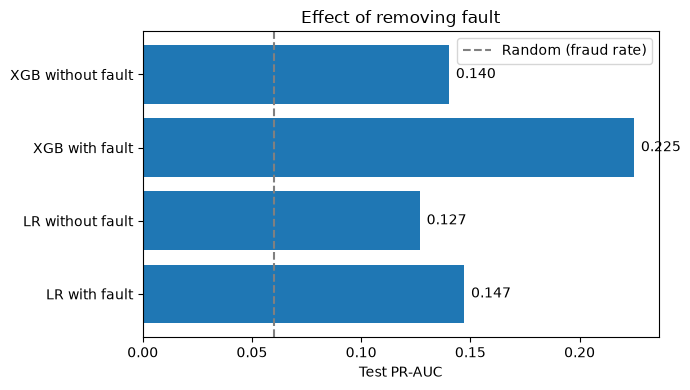

In [17]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(fault_df.index, fault_df["pr_auc"])
ax.axvline(y_test.mean(), color="grey", linestyle="--", label="Random (fraud rate)")
ax.set_xlabel("Test PR-AUC")
ax.set_title("Effect of removing fault")
ax.legend()
for i, v in enumerate(fault_df["pr_auc"]):
    ax.text(v + 0.003, i, f"{v:.3f}", va="center")
plt.tight_layout()
fig.savefig("../reports/fault_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

- Flag rate tradeoff

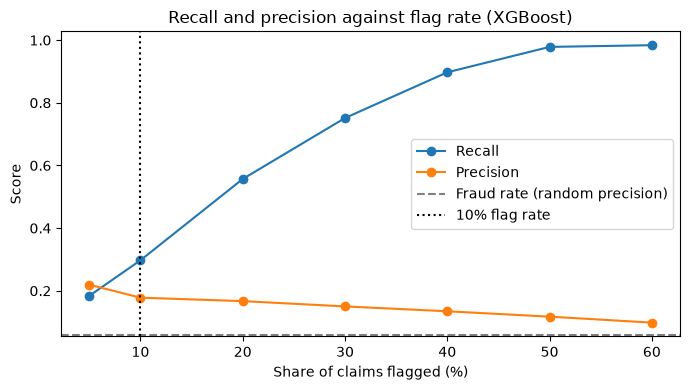

In [ ]:

from insurance_fraud_detection.evaluate import top_frac_capture

total_fraud = int(y_test.sum())
fracs = [0.05, 0.10, 0.20, 0.30, 0.40, 0.50, 0.60]

recall, precision = [], []
for f in fracs:
    caught = top_frac_capture(y_test, xgb_scores, f)
    flagged = int(np.ceil(len(y_test) * f))
    recall.append(caught / total_fraud)
    precision.append(caught / flagged)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot([f * 100 for f in fracs], recall, marker="o", label="Recall")
ax.plot([f * 100 for f in fracs], precision, marker="o", label="Precision")
ax.axhline(y_test.mean(), color="grey", linestyle="--", label="Fraud rate (random precision)")
ax.axvline(10, color="black", linestyle=":", label="10% flag rate")
ax.set_xlabel("Share of claims flagged (%)")
ax.set_ylabel("Score")
ax.set_title("Recall and precision against flag rate (XGBoost)")
ax.legend()
plt.tight_layout()
fig.savefig("../reports/flag_rate_tradeoff.png", dpi=150, bbox_inches="tight")
plt.show()

- Feature comparison

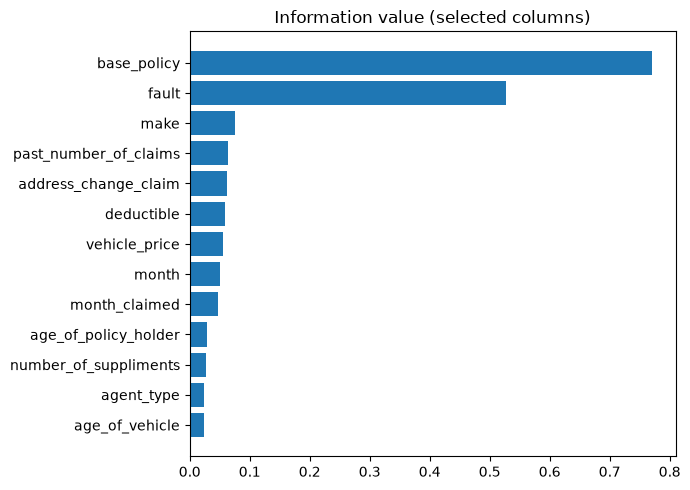

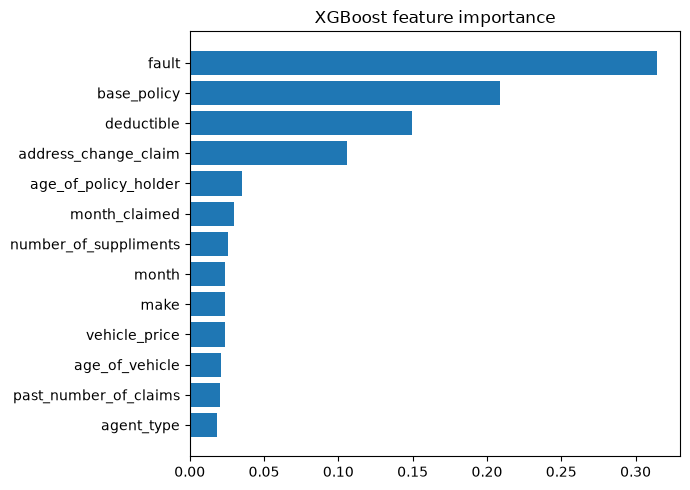

In [ ]:


def hbar(values: pd.Series, title: str) -> None:
    values = values.sort_values()
    fig, ax = plt.subplots(figsize=(7, 5))
    ax.barh(values.index, values.values)
    ax.set_title(title)
    plt.tight_layout()
    fig.savefig("../reports/feature_importance.png", dpi=150, bbox_inches="tight")
    plt.show()

# iv: a Series of IV indexed by column name
hbar(iv[SELECTED_COLS], "Information value (selected columns)")

xgb_pipe.fit(X_train, y_train)
imp = pd.Series(xgb_pipe["clf"].feature_importances_, index=SELECTED_COLS)
hbar(imp, "XGBoost feature importance")

- PR ROC curves

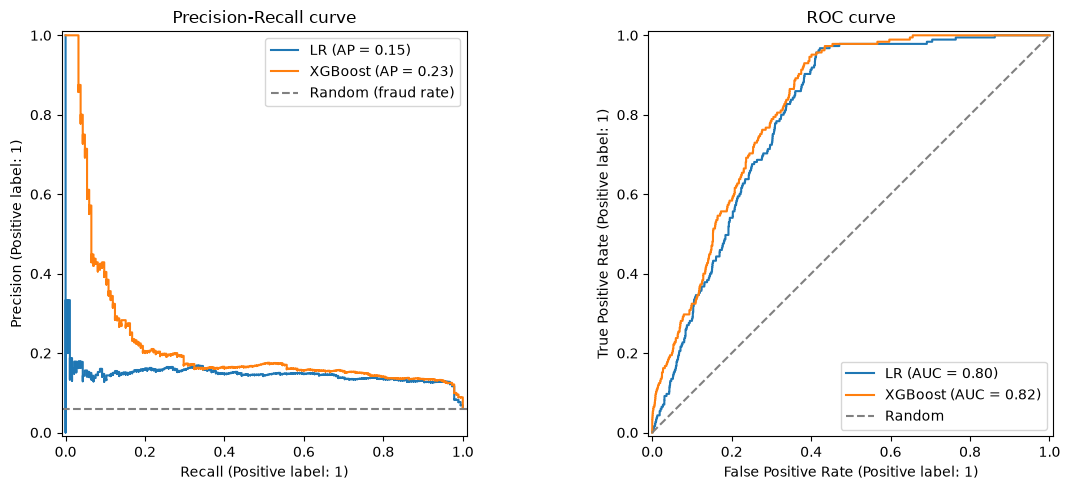

In [ ]:
from sklearn.metrics import PrecisionRecallDisplay, RocCurveDisplay

fig, ax = plt.subplots(1, 2, figsize=(12, 5))

for name, scores in [("LR", lr_scores), ("XGBoost", xgb_scores)]:
    PrecisionRecallDisplay.from_predictions(y_test, scores, name=name, ax=ax[0])
    RocCurveDisplay.from_predictions(y_test, scores, name=name, ax=ax[1])

# random baselines
ax[0].axhline(y_test.mean(), color="grey", linestyle="--", label="Random (fraud rate)")
ax[1].plot([0, 1], [0, 1], color="grey", linestyle="--", label="Random")

ax[0].set_title("Precision-Recall curve")
ax[1].set_title("ROC curve")
ax[0].legend()
ax[1].legend()
plt.tight_layout()
fig.savefig("../reports/pr_roc_curves.png", dpi=150, bbox_inches="tight")
plt.show()

## Modelling notes

**Setup**
- 13 selected columns, WOE-encoded inside the Pipeline, so WOE is learned from training folds only (no leak).
- 5-fold stratified CV on train, scored by PR-AUC. Test set scored once at the end.
- Fraud rate is about 6%, so a random model scores PR-AUC of about 0.06.

**Results (test)**
| Model | CV PR-AUC | Test PR-AUC | ROC-AUC | Gini | KS | Top 10% caught |
|---|---|---|---|---|---|---|
| LR | 0.159 | 0.147 | 0.796 | 0.591 | 0.546 | 50/185 |
| XGBoost | 0.219 | 0.225 | 0.818 | 0.635 | 0.551 | 55/185 |

**Fault comparison**
- Without `fault`: **LR PR-AUC:** 0.127, **XGBoost PR-AUC:** 0.14
- Meaning: Most of the model’s ability comes from **fault**. Without it, performance falls close to the logistic regression level, so  the model leans heavily on one feature.

**What I learnt**
- "Top 10%" means flag the 309 highest-scoring claims and count the real frauds among them.
- Recall depends on the flag rate, so recall figures are only comparable at the same rate.
- XGBoost beats LR on every fold, likely because of interactions (not tested).



- For the APP

In [25]:
from insurance_fraud_detection.config import TARGET
from insurance_fraud_detection.data_prep import drop_bad_rows, load_data, split_data

_, test_raw = split_data(load_data())
test_raw = drop_bad_rows(test_raw)

test_raw.iloc[0].drop(TARGET).to_dict()

{'month': 'Jul',
 'week_of_month': 1,
 'day_of_week': 'Thursday',
 'make': 'Chevrolet',
 'accident_area': 'Urban',
 'day_of_week_claimed': 'Friday',
 'month_claimed': 'Jul',
 'week_of_month_claimed': 3,
 'sex': 'Male',
 'marital_status': 'Married',
 'age': 41,
 'fault': 'Policy Holder',
 'policy_type': 'Sedan - Liability',
 'vehicle_category': 'Sport',
 'vehicle_price': '20000 to 29000',
 'deductible': 400,
 'driver_rating': 4,
 'days_policy_accident': 'more than 30',
 'days_policy_claim': 'more than 30',
 'past_number_of_claims': 'none',
 'age_of_vehicle': '7 years',
 'age_of_policy_holder': '36 to 40',
 'police_report_filed': 'No',
 'witness_present': 'No',
 'agent_type': 'External',
 'number_of_suppliments': 'none',
 'address_change_claim': 'no change',
 'number_of_cars': '1 vehicle',
 'year': 1995,
 'base_policy': 'Liability'}

In [24]:
from insurance_fraud_detection.config import SELECTED_COLS
from insurance_fraud_detection.data_prep import load_data

raw = load_data()
raw = raw[raw["month_claimed"] != "0"]          # the one bad row

months = ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
          "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

options = {}
for c in SELECTED_COLS:
    if c == "deductible":
        options[c] = sorted(int(x) for x in raw[c].unique())
    elif c in ("month", "month_claimed"):
        options[c] = months
    else:
        options[c] = list(raw[c].astype(str).value_counts().index)  # most common first

print("OPTIONS = {")
for k, v in options.items():
    print(f"    {k!r}: {v!r},")
print("}")

OPTIONS = {
    'base_policy': ['Collision', 'Liability', 'All Perils'],
    'fault': ['Policy Holder', 'Third Party'],
    'make': ['Pontiac', 'Toyota', 'Honda', 'Mazda', 'Chevrolet', 'Accura', 'Ford', 'VW', 'Dodge', 'Saab', 'Mercury', 'Saturn', 'Nisson', 'BMW', 'Jaguar', 'Porche', 'Mecedes', 'Ferrari', 'Lexus'],
    'past_number_of_claims': ['2 to 4', 'none', '1', 'more than 4'],
    'address_change_claim': ['no change', '4 to 8 years', '2 to 3 years', '1 year', 'under 6 months'],
    'deductible': [300, 400, 500, 700],
    'vehicle_price': ['20000 to 29000', '30000 to 39000', 'more than 69000', 'less than 20000', '40000 to 59000', '60000 to 69000'],
    'month': ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec'],
    'month_claimed': ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec'],
    'age_of_policy_holder': ['31 to 35', '36 to 40', '41 to 50', '51 to 65', '26 to 30', 'over 65', '16 to 17', '21 to 25', '18 to 20